[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/05-deep-learning-llms/05_embeddings.ipynb)

*Deep Learning & LLMs · Notebook 5 of 10*

# Tokens & Embeddings

How text becomes numbers: tokenising, BPE merges, bag of words and TF-IDF, embedding tables, skip-gram and negative sampling, word analogies, co-occurrence and positional encoding.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** An embedding gives each word coordinates on a map of meaning, so similar words live close together.

**What interviewers really test here:** Tokenisation, word2vec, cosine similarity and static vs contextual embeddings.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. From text to numbers: tokens *(Basics)*
- [ ] 2. Byte-pair encoding, by hand *(Core)*
- [ ] 3. Bag of words and TF-IDF *(Core)*
- [ ] 4. Embeddings: a learned table of vectors *(Core)*
- [ ] 5. You shall know a word by its neighbours *(Core)*
- [ ] 6. Word2vec: skip-gram with negative sampling *(Core)*
- [ ] 7. Sentence embeddings and positions *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Text representations compared

| Method | Size | Knows meaning? | Good for |
| --- | --- | --- | --- |
| One-hot | vocabulary | no | teaching |
| Bag of words / TF-IDF | vocabulary, sparse | no | keyword search, simple classifiers |
| Word2vec / GloVe | about 300 | one sense per word | light features |
| Transformer embeddings | hundreds to thousands | depends on context | semantic search, RAG |

### Tokeniser facts for LLM work

- Pricing and context limits are in tokens.
- 4 characters per token is a rough English estimate. Languages other than English and code can differ considerably.
- Use a model's own tokeniser or token-counting API when accuracy matters.
- Token ids aren't portable: a model must use the tokeniser it was trained with.
- Decide deliberately how to truncate. Cutting the end of a document might remove what you need.

### Formulas

| Quantity | Formula |
| --- | --- |
| TF-IDF | (count / length) × ln(N / df) |
| PMI | ln(c·N / (x·y)) |
| Cosine | a·b / (‖a‖·‖b‖) |
| Negative sampling | −ln σ(c·p) − Σ ln σ(−c·n) |
| Table size | vocabulary × dimension |



TF-IDF has many variants, so libraries such as scikit-learn give somewhat different numbers.

---
# Part 2: Lessons, step by step

## Lesson 1: From text to numbers: tokens

*Level: Basics*

Neural networks need numbers. The journey from text is always the same:



**text → tokens → ids → vectors**



What counts as a token is a real design decision:



| Level | "unhappily" becomes | Vocabulary | Weakness |
| --- | --- | --- | --- |
| Characters | u, n, h, a, p, p, i, l, y | tiny (about 100) | long sequences; has to learn spelling first |
| Words | unhappily | huge | any unseen word is unknown |
| Subwords | un, happ, ily | tens of thousands | splits can look odd |



Modern LLMs use subwords, because a new word can still be built from known pieces.



**A vocabulary by hand.** Tokens b, a, b, c, a, b with min\_count = 2: a appears 2 times, b 3 times, c once, so c is dropped.



The vocabulary is &lt;pad&gt; = 0, &lt;unk&gt; = 1, a = 2, b = 3. Encoding a, z, b gives **[2, 1, 3]**, since z becomes unknown. Special tokens matter: padding fills batches, and "unknown" stops unseen words crashing the code.



A simple word tokeniser turns "Hello, World! It's 2024." into hello, world, it, s, 2024. Notice "It's" split in two, and the punctuation gone. Every choice loses something.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 2: Byte-pair encoding, by hand

*Level: Core*

**BPE** is the method behind most LLM tokenisers. It learns subwords directly from data:



1. Start with every word split into characters.
2. Count neighbouring pairs across the corpus.
3. Merge the most frequent pair into one token.
4. Repeat until the vocabulary is the size you want.



Words: low, lower, newest, widest.



**Round 1:** Pair counts include l-o: 2, o-w: 2, w-e: 2, e-s: 2, s-t: 2, all tied. Breaking ties alphabetically, we merge **e + s → es**.



**Round 2:** Now es-t appears twice, and it's the alphabetically first of the top pairs. Merge **es + t → est**.



**Round 3:** Merge **l + o → lo**.



| Word | Start | After 3 merges |
| --- | --- | --- |
| low | l o w | lo w |
| lower | l o w e r | lo w e r |
| newest | n e w e s t | n e w est |
| widest | w i d e s t | w i d est |



It has discovered "est" as a useful ending, without being told about English. To tokenise new text, you replay the merges in the same order. An unseen word like "slowest" still works, built from known pieces.



Real tokenisers differ in details (real tie-breaking usually isn't alphabetical, for example), and the same text can be a different number of tokens under different tokenisers.



**Why you should care as an LLM developer:**



- **You're billed and limited by tokens**, not characters. English averages roughly 4 characters per token, so "Hello there" (11 characters) is about 3. That's only a quick guess; use your provider's token counter for real limits.
- **Models see tokens, not letters.** That's one reason counting the letters in a word can be surprisingly hard for them.

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q12](#q12), [Q19](#q19), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 3: Bag of words and TF-IDF

*Level: Core*

Before embeddings, there were counts. They're still useful: search and RAG both rely on them, as you'll see later.



Three documents: "the cat sat", "the dog sat", "the dog ran fast".



|   | cat | dog | fast | ran | sat | the |
| --- | --- | --- | --- | --- | --- | --- |
| Doc 0 | 1 | 0 | 0 | 0 | 1 | 1 |
| Doc 1 | 0 | 1 | 0 | 0 | 1 | 1 |
| Doc 2 | 0 | 1 | 1 | 1 | 0 | 1 |



But "the" tells you nothing, since it's everywhere. **TF-IDF** rewards words that are frequent here but rare overall:



**tf-idf = (count ÷ doc length) × ln(documents ÷ documents containing it)**



| Word, doc | tf | idf | Score |
| --- | --- | --- | --- |
| "cat", doc 0 | 1/3 | ln(3/1) = 1.0986 | **0.3662** |
| "dog", doc 2 | 1/4 | ln(3/2) = 0.4055 | **0.1014** |
| "the", doc 0 | 1/3 | ln(3/3) = 0 | **0** |



The rare word gets the highest score, and the universal one gets exactly zero.



**The limitation:** "car" and "automobile" are as different here as "car" and "banana", because each word is just a separate column. It knows nothing about meaning. Embeddings fix that.

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 4: Embeddings: a learned table of vectors

*Level: Core*

A one-hot vector for 50,000 words is 50,000 numbers long, and every pair of words is equally far apart. An **embedding table** replaces this with a short, learned vector per token:



```python
E = [[0.1, 0.2],     # id 0
     [0.3, 0.4],     # id 1
     [0.5, 0.6]]     # id 2

ids [2, 0, 2]  →  [[0.5, 0.6], [0.1, 0.2], [0.5, 0.6]]
```



That's all an embedding layer is: looking up rows. It's equivalent to multiplying a one-hot vector by the table, but much faster. The numbers start random and are trained with the rest of the model.



**Cost:** vocabulary × dimension. With 50,000 × 768 that's 38,400,000 parameters, or **153.6 MB** at 4 bytes each. It's often a large fraction of a small model.



**The payoff** is that similar words end up with similar vectors, so you can measure meaning with cosine similarity. With the small table in the practice questions:



- king = (0.9, 0.8, 0.1), man = (0.5, 0.9, 0.1): 1.18 / (1.2083 × 1.0344) = **0.944**.
- king and queen = (0.9, 0.1, 0.8): 0.97 / 1.46 = **0.664**.



In this toy table, the second dimension acts like "male". Real dimensions don't usually have such neat meanings.



**Analogies:** king − man + woman = (0.9, 0, 0.9). Its cosine with queen is **0.995**, the closest among the remaining words. A caveat: analogy code excludes the input words, and in real embeddings the nearest result is often just "king" without that exclusion. So analogies are an appealing demo, not proof that the model understands relations.

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q7](#q7), [Q13](#q13), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 5: You shall know a word by its neighbours

*Level: Core*

How can a machine learn meaning with no dictionary? From one observation: **words that appear in similar contexts have similar meanings**. "I drank a cup of \_\_\_" tells you the gap is a drink.



**Counting method.** Count how often words appear near one another. For a, b, a, c with window 1:



|   | a | b | c |
| --- | --- | --- | --- |
| a | 0 | 2 | 1 |
| b | 2 | 0 | 0 |
| c | 1 | 0 | 0 |



But common words dominate raw counts. **Pointwise mutual information** asks whether a pair appears more than chance would predict:



**PMI = ln( P(x, y) / (P(x)·P(y)) )**



With x seen 20 times, y 30 times and N = 300 pairs:



- Together 10 times: ln(10·300 / (20·30)) = ln 5 = **1.609**: a real association.
- Together 2 times: ln(2·300 / 600) = ln 1 = **0**: exactly what chance predicts.



Keep the positive PMI values and compress the table with SVD, and each row becomes a compact word vector. The chart does this on eight short sentences, and shows the similarity of the resulting vectors. Cat and dog score high, as do car and truck, while pairs across those groups score low, though no one told it those categories. The corpus is tiny and built to make the pattern clear, so this demonstrates the idea and isn't a useful model.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

[[1.   1.   0.12 0.12]
 [1.   1.   0.12 0.12]
 [0.12 0.12 1.   1.  ]
 [0.12 0.12 1.   1.  ]]


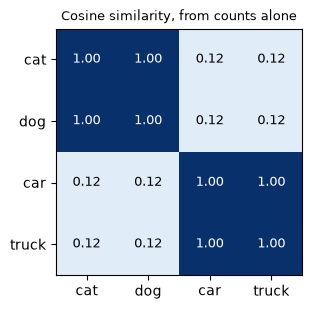

In [2]:
def word_map():
    sentences = ["the cat drinks milk", "the dog drinks water", "the cat eats fish", "the dog eats meat",
                 "the car needs fuel", "the truck needs fuel", "the car uses road", "the truck uses road"]
    words = sorted({w for s in sentences for w in s.split()})
    index = {w: i for i, w in enumerate(words)}
    counts = np.zeros((len(words), len(words)))
    for s in sentences:
        tokens = s.split()
        for i, t in enumerate(tokens):
            for j in range(max(0, i - 2), min(len(tokens), i + 3)):
                if i != j:
                    counts[index[t], index[tokens[j]]] += 1
    total = counts.sum()
    row = counts.sum(axis=1, keepdims=True)
    with np.errstate(divide="ignore"):
        pmi = np.log(counts * total / (row @ row.T))
    ppmi = np.maximum(pmi, 0)
    U, S, _ = np.linalg.svd(ppmi)
    vectors = U[:, :3] * S[:3]
    show = ["cat", "dog", "car", "truck"]
    picked = vectors[[index[w] for w in show]]
    unit = picked / np.linalg.norm(picked, axis=1, keepdims=True)
    similarity = unit @ unit.T
    print(similarity.round(2))
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4), show)
    ax.set_yticks(range(4), show)
    for r in range(4):
        for c in range(4):
            ax.text(c, r, f"{similarity[r, c]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if similarity[r, c] > 0.6 else "black")
    ax.set_title("Cosine similarity, from counts alone", fontsize=9)


word_map()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 6: Word2vec: skip-gram with negative sampling

*Level: Core*

Instead of counting and compressing, **word2vec** learns vectors by making a simple prediction: given a word, is this other word nearby?



**Training pairs:** for "the cat sat" with window 1: (the, cat), (cat, the), (cat, sat), (sat, cat).



Predicting across a whole vocabulary would be slow, so **negative sampling** turns this into a yes/no question: score the real context word high, and a few random words low.



**loss = −ln σ(c·p) − Σ ln σ(−c·n)**



With centre c = (1, 0), true context p = (1, 0), and negatives (−1, 0) and (0, 1):



<table><tr><th>Word</th><th>Dot with c</th><th>Term</th><th>Value</th></tr> <tr><td>True context</td><td>1</td><td>−ln σ(1)</td><td>0.3133</td></tr> <tr><td>Negative 1</td><td>−1</td><td>−ln σ(1)</td><td>0.3133</td></tr> <tr><td>Negative 2</td><td>0</td><td>−ln σ(0)</td><td>0.6931</td></tr> <tr><td colspan="3"><b>Total</b></td><td><b>1.3197</b></td></tr></table>



Negative 2 costs most: it's at right angles, neither pushed away nor pulled. Training raises the dot with real neighbours and lowers it with random words.



This is an early, simple form of **contrastive learning**, and it's still the core idea in modern embedding models: pull related things together, push unrelated things apart.



**Static vs contextual:** word2vec gives "bank" one vector, whether it's a river bank or a money bank. Transformer models produce a different vector for each occurrence, based on its surroundings. That's the main reason they replaced it.

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 7: Sentence embeddings and positions

*Level: Advanced*

**From tokens to one vector.** Search and RAG need one vector per text. The usual way is mean pooling (ignoring padding), then scaling to length 1:



- Tokens (3, 0), (0, 4), and a padding row (9, 9).
- Mean of real tokens: (1.5, 2).
- Length: √(1.5² + 2²) = 2.5.
- Result: **(0.6, 0.8)**.



After scaling, cosine similarity is just a dot product, which is why vector databases love it. If padding is left in, the result changes completely, and two identical texts in different batches get different vectors.



**Giving order back.** Attention, in the next topic, treats its input as an unordered set, so position has to be added explicitly. The original transformer used fixed sine waves:



| Position | sin(pos) | cos(pos) | sin(pos/100) | cos(pos/100) |
| --- | --- | --- | --- | --- |
| 0 | 0 | 1 | 0 | 1 |
| 1 | 0.8415 | 0.5403 | 0.01 | 1.0 |
| 2 | 0.9093 | −0.4161 | 0.02 | 0.9998 |



(These are n = 3, d = 4, where the rate for the second pair is 10000^(2/4) = 100.)



Think of a clock: the fast hand separates nearby positions, slow hands separate distant ones, and the chart shows these bands. Many models now use **learned position embeddings** or other schemes instead, but the purpose is the same.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

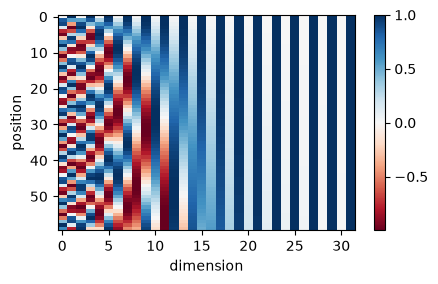

In [3]:
def position_bands():
    n, d = 60, 32
    pos = np.arange(n)[:, None]
    rates = 10000 ** (np.arange(0, d, 2) / d)
    pe = np.zeros((n, d))
    pe[:, 0::2] = np.sin(pos / rates)
    pe[:, 1::2] = np.cos(pos / rates)
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    image = ax.imshow(pe, aspect="auto", cmap="RdBu")
    fig.colorbar(image, ax=ax)
    ax.set_xlabel("dimension")
    ax.set_ylabel("position")


position_bands()

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q18](#q18). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [4]:
import re


<a id="q1"></a>
### Q1. Word Tokeniser

🟢 Warm-up · *Splitting text*

Lower-case the text and return its runs of letters or digits as tokens.

**Examples**

- `text = "Hello, World! It's 2024."` → `['hello', 'world', 'it', 's', '2024']`

In [ ]:
def tokenise(text):
    """
    Lower-case the text and return its runs of letters or digits as tokens.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tokenise, [
    (("Hello, World! It's 2024.",), ['hello', 'world', 'it', 's', '2024']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk the characters, building words.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`re.findall(r'[a-z0-9]+', text.lower())`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Walk the characters, building words.

```python
def tokenise(text):
    tokens, current = [], ""
    for ch in text.lower():
        if ("a" <= ch <= "z") or ("0" <= ch <= "9"):
            current += ch
        elif current:
            tokens.append(current)
            current = ""
    if current:
        tokens.append(current)
    return tokens
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `re.findall(r'[a-z0-9]+', text.lower())`.

```python
def tokenise(text):
    return re.findall(r"[a-z0-9]+", text.lower())
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk the characters, building words. That costs O(n) time and O(n) space."

"I can do better: `re.findall(r'[a-z0-9]+', text.lower())`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/word-tokeniser)

<a id="q2"></a>
### Q2. Build a Vocabulary

🟢 Warm-up · *With special tokens*

Return {token: id}: 0 = &lt;pad&gt;, 1 = &lt;unk&gt;, then tokens appearing at least min\_count times, sorted alphabetically.

**Examples**

- `tokens = ['b', 'a', 'b', 'c', 'a', 'b'], min_count = 2` → `{'<pad>': 0, '<unk>': 1, 'a': 2, 'b': 3}`

In [ ]:
def build_vocab(tokens, min_count):
    """
    Return {token: id}: 0 = <pad>, 1 = <unk>, then tokens appearing at least
    min_count times, sorted alphabetically.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(build_vocab, [
    ((['b', 'a', 'b', 'c', 'a', 'b'], 2), {'<pad>': 0, '<unk>': 1, 'a': 2, 'b': 3}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a dictionary, filter, sort.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.unique` with counts.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count in a dictionary, filter, sort.

```python
def build_vocab(tokens, min_count):
    counts = {}
    for t in tokens:
        counts[t] = counts.get(t, 0) + 1
    vocab = {"<pad>": 0, "<unk>": 1}
    for t in sorted(counts):
        if counts[t] >= min_count:
            vocab[t] = len(vocab)
    return vocab
```

**Cost:** O(n + k log k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.unique` with counts.

```python
def build_vocab(tokens, min_count):
    words, counts = np.unique(tokens, return_counts=True)
    kept = words[counts >= min_count].tolist()
    return {"<pad>": 0, "<unk>": 1, **{w: i + 2 for i, w in enumerate(kept)}}
```

**Cost:** O(n log n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a dictionary, filter, sort. That costs O(n + k log k) time and O(k) space."

"I can do better: `np.unique` with counts. That's O(n log n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/build-a-vocabulary)

<a id="q3"></a>
### Q3. Encode With Unknowns

🟢 Warm-up · *Unseen words*

Map tokens to ids, using 1 for anything not in the vocabulary.

**Examples**

- `tokens = ['a', 'z', 'b'], vocab = {'<pad>': 0, '<unk>': 1, 'a': 2, 'b': 3}` → `[2, 1, 3]`

In [ ]:
def encode(tokens, vocab):
    """
    Map tokens to ids, using 1 for anything not in the vocabulary.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(encode, [
    ((['a', 'z', 'b'], {'<pad>': 0, '<unk>': 1, 'a': 2, 'b': 3}), [2, 1, 3]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with an if.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`dict.get(t, 1)` in a comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop with an if.

```python
def encode(tokens, vocab):
    out = []
    for t in tokens:
        if t in vocab:
            out.append(vocab[t])
        else:
            out.append(1)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `dict.get(t, 1)` in a comprehension.

```python
def encode(tokens, vocab):
    return [vocab.get(t, 1) for t in tokens]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with an if. That costs O(n) time and O(n) space."

"I can do better: `dict.get(t, 1)` in a comprehension. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/encode-with-unknowns)

<a id="q4"></a>
### Q4. Bag of Words

🟢 Warm-up · *Counts per document*

Return one row per document, counting each vocabulary word (columns = sorted distinct words).

**Examples**

- `docs = [['the', 'cat', 'sat'], ['the', 'dog', 'sat'], ['the', 'dog', 'ran', 'fast']]` → `[[1, 0, 0, 0, 1, 1], [0, 1, 0, 0, 1, 1], [0, 1, 1, 1, 0, 1]]`

In [ ]:
def bag_of_words(docs):
    """
    Return one row per document, counting each vocabulary word (columns = sorted
    distinct words).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bag_of_words, [
    (([['the', 'cat', 'sat'], ['the', 'dog', 'sat'], ['the', 'dog', 'ran', 'fast']],), [[1, 0, 0, 0, 1, 1], [0, 1, 0, 0, 1, 1], [0, 1, 1, 1, 0, 1]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Index dict + `np.add.at`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops.

```python
def bag_of_words(docs):
    vocab = sorted({w for d in docs for w in d})
    return [[d.count(w) for w in vocab] for d in docs]
```

**Cost:** O(n·V) time, O(n·V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Index dict + `np.add.at`.

```python
def bag_of_words(docs):
    vocab = {w: i for i, w in enumerate(sorted({w for d in docs for w in d}))}
    out = np.zeros((len(docs), len(vocab)), dtype=int)
    for i, d in enumerate(docs):
        np.add.at(out[i], [vocab[w] for w in d], 1)
    return out
```

**Cost:** O(words) time, O(n·V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(n·V) time and O(n·V) space."

"I can do better: Index dict + `np.add.at`. That's O(words) time and O(n·V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/bag-of-words)

<a id="q5"></a>
### Q5. Rough Token Estimate

🟢 Warm-up · *Before you call an API*

A rule of thumb for English is about 4 characters per token. Return (estimate per text rounded up, the total).

**Examples**

- `texts = ['Hello there', 'Tokenisers split text into pieces']` → `([3, 9], 12)`

In [ ]:
def estimate_tokens(texts):
    """
    A rule of thumb for English is about 4 characters per token. Return
    (estimate per text rounded up, the total).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(estimate_tokens, [
    ((['Hello there', 'Tokenisers split text into pieces'],), ([3, 9], 12)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide and round up in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.ceil` on an array of lengths.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Divide and round up in a loop.

```python
def estimate_tokens(texts):
    out = [math.ceil(len(t) / 4) for t in texts]
    return (out, sum(out))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.ceil` on an array of lengths.

```python
def estimate_tokens(texts):
    n = np.ceil(np.array([len(t) for t in texts]) / 4).astype(int)
    return (n, int(n.sum()))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide and round up in a loop. That costs O(n) time and O(n) space."

"I can do better: `np.ceil` on an array of lengths. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/rough-token-estimate)

<a id="q6"></a>
### Q6. Embedding Lookup

🟢 Warm-up · *A table of vectors*

Return the embedding rows for the given token ids.

**Examples**

- `E = [[0.1, 0.2], [0.3, 0.4], [0.5, 0.6]], ids = [2, 0, 2]` → `[[0.5, 0.6], [0.1, 0.2], [0.5, 0.6]]`

In [ ]:
def lookup(E, ids):
    """
    Return the embedding rows for the given token ids.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lookup, [
    (([[0.1, 0.2], [0.3, 0.4], [0.5, 0.6]], [2, 0, 2]), [[0.5, 0.6], [0.1, 0.2], [0.5, 0.6]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list of rows in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`E[ids]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A list of rows in a loop.

```python
def lookup(E, ids):
    return [E[i] for i in ids]
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `E[ids]`.

```python
def lookup(E, ids):
    return np.array(E)[ids]
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list of rows in a loop. That costs O(T·d) time and O(T·d) space."

"I can do better: `E[ids]`. That's O(T·d) time and O(T·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/embedding-lookup)

<a id="q7"></a>
### Q7. Embedding Table Size

🟢 Warm-up · *It adds up*

Return (parameters, MB at 4 bytes each) for a vocabulary and dimension, with MB rounded to 2 decimals (1 MB = 10⁶ bytes).

**Examples**

- `vocab = 50000, dim = 768` → `(38400000, 153.6)`
- `vocab = 30000, dim = 128` → `(3840000, 15.36)`

In [ ]:
def embedding_size(vocab, dim):
    """
    Return (parameters, MB at 4 bytes each) for a vocabulary and dimension, with
    MB rounded to 2 decimals (1 MB = 10⁶ bytes).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(embedding_size, [
    ((50000, 768), (38400000, 153.6)),
    ((30000, 128), (3840000, 15.36)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Create a zero table of float32 and read `.nbytes` (small cases only).

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply.

```python
def embedding_size(vocab, dim):
    params = vocab * dim
    return (params, round(params * 4 / 1e6, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Create a zero table of float32 and read `.nbytes` (small cases only).

```python
def embedding_size(vocab, dim):
    params = int(np.prod([vocab, dim]))
    return (params, round(params * np.float32(0).nbytes / 1e6, 2))
```

**Cost:** O(1) time, O(V·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply. That costs O(1) time and O(1) space."

"I can do better: Create a zero table of float32 and read `.nbytes` (small cases only). That's O(1) time and O(V·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/embedding-table-size)

<a id="q8"></a>
### Q8. Skip-Gram Pairs

🟢 Warm-up · *Word2vec's training data*

For each position, pair the word with every word within the window on either side. Return (centre, context) pairs in order.

**Examples**

- `tokens = ['the', 'cat', 'sat'], window = 1` → `[('the', 'cat'), ('cat', 'the'), ('cat', 'sat'), ('sat', 'cat')]`

In [ ]:
def skip_gram(tokens, window):
    """
    For each position, pair the word with every word within the window on either
    side. Return (centre, context) pairs in order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(skip_gram, [
    ((['the', 'cat', 'sat'], 1), [('the', 'cat'), ('cat', 'the'), ('cat', 'sat'), ('sat', 'cat')]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops with bounds.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension using slices.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops with bounds.

```python
def skip_gram(tokens, window):
    pairs = []
    for i in range(len(tokens)):
        for j in range(max(0, i - window), min(len(tokens), i + window + 1)):
            if j != i:
                pairs.append((tokens[i], tokens[j]))
    return pairs
```

**Cost:** O(T·w) time, O(T·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension using slices.

```python
def skip_gram(tokens, window):
    n = len(tokens)
    return [(tokens[i], tokens[j]) for i in range(n) for j in np.arange(max(0, i - window), min(n, i + window + 1)).tolist() if j != i]
```

**Cost:** O(T·w) time, O(T·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops with bounds. That costs O(T·w) time and O(T·w) space."

"I can do better: A comprehension using slices. That's O(T·w) time and O(T·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/skip-gram-pairs)

<a id="q9"></a>
### Q9. Truncate and Pad to a Fixed Length

🟢 Warm-up · *Every model has a limit*

Cut each id list to max\_len, then pad on the right with 0 to exactly max\_len.

**Examples**

- `seqs = [[1, 2, 3, 4], [5]], max_len = 3` → `[[1, 2, 3], [5, 0, 0]]`

In [ ]:
def fit_length(seqs, max_len):
    """
    Cut each id list to max_len, then pad on the right with 0 to exactly
    max_len.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fit_length, [
    (([[1, 2, 3, 4], [5]], 3), [[1, 2, 3], [5, 0, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slice, then add zeros, in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fill a zero matrix of shape (n, max\_len).

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Slice, then add zeros, in a loop.

```python
def fit_length(seqs, max_len):
    out = []
    for s in seqs:
        cut = s[:max_len]
        out.append(cut + [0] * (max_len - len(cut)))
    return out
```

**Cost:** O(n·L) time, O(n·L) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Fill a zero matrix of shape (n, max\_len).

```python
def fit_length(seqs, max_len):
    out = np.zeros((len(seqs), max_len), dtype=int)
    for i, s in enumerate(seqs):
        cut = s[:max_len]
        out[i, :len(cut)] = cut
    return out
```

**Cost:** O(n·L) time, O(n·L) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slice, then add zeros, in a loop. That costs O(n·L) time and O(n·L) space."

"I can do better: Fill a zero matrix of shape (n, max\_len). That's O(n·L) time and O(n·L) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/truncate-and-pad-to-a-fixed-length)

<a id="q10"></a>
### Q10. TF-IDF

🟡 Interview standard · *Rare words count more*

Score word w in document i: (count in doc / doc length) × ln(number of docs / docs containing w). Round to 4 decimals.

**Examples**

- `docs = [['the', 'cat', 'sat'], ['the', 'dog', 'sat'], ['the', 'dog', 'ran', 'fast']], i = 0, w = 'cat'` → `0.3662`
- `docs = [['the', 'cat', 'sat'], ['the', 'dog', 'sat'], ['the', 'dog', 'ran', 'fast']], i = 0, w = 'the'` → `0.0`
- `docs = [['the', 'cat', 'sat'], ['the', 'dog', 'sat'], ['the', 'dog', 'ran', 'fast']], i = 2, w = 'dog'` → `0.1014`

In [ ]:
def tfidf(docs, i, w):
    """
    Score word w in document i: (count in doc / doc length) × ln(number of docs
    / docs containing w). Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tfidf, [
    (([['the', 'cat', 'sat'], ['the', 'dog', 'sat'], ['the', 'dog', 'ran', 'fast']], 0, 'cat'), 0.3662),
    (([['the', 'cat', 'sat'], ['the', 'dog', 'sat'], ['the', 'dog', 'ran', 'fast']], 0, 'the'), 0.0),
    (([['the', 'cat', 'sat'], ['the', 'dog', 'sat'], ['the', 'dog', 'ran', 'fast']], 2, 'dog'), 0.1014),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count with loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Bag-of-words matrix, then column operations.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count with loops.

```python
def tfidf(docs, i, w):
    tf = docs[i].count(w) / len(docs[i])
    df = sum(1 for d in docs if w in d)
    return round(tf * math.log(len(docs) / df), 4) + 0.0
```

**Cost:** O(total words) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Bag-of-words matrix, then column operations.

```python
def tfidf(docs, i, w):
    has = np.array([w in d for d in docs])
    tf = docs[i].count(w) / len(docs[i])
    return round(tf * np.log(len(docs) / has.sum()), 4) + 0.0
```

**Cost:** O(n·V) time, O(n·V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count with loops. That costs O(total words) time and O(1) space."

"I can do better: Bag-of-words matrix, then column operations. That's O(n·V) time and O(n·V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/tf-idf)

<a id="q11"></a>
### Q11. BPE: Most Frequent Pair

🟡 Interview standard · *How tokenisers are built*

words is a list of token lists. Count neighbouring pairs and return the most frequent (ties → first alphabetically), with its count.

**Examples**

- `words = [['l', 'o', 'w'], ['l', 'o', 'w', 'e', 'r'], ['n', 'e', 'w']]` → `(('l', 'o'), 2)`

In [ ]:
def top_pair(words):
    """
    words is a list of token lists. Count neighbouring pairs and return the most
    frequent (ties → first alphabetically), with its count.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_pair, [
    (([['l', 'o', 'w'], ['l', 'o', 'w', 'e', 'r'], ['n', 'e', 'w']],), (('l', 'o'), 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary of pair counts.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`collections.Counter` over `zip`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A dictionary of pair counts.

```python
def top_pair(words):
    counts = {}
    for w in words:
        for pair in zip(w, w[1:]):
            counts[pair] = counts.get(pair, 0) + 1
    best = max(counts.values())
    pair = min(p for p, c in counts.items() if c == best)
    return (pair, best)
```

**Cost:** O(total) time, O(pairs) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `collections.Counter` over `zip`.

```python
def top_pair(words):
    from collections import Counter
    counts = Counter(p for w in words for p in zip(w, w[1:]))
    return min(counts.items(), key=lambda kv: (-kv[1], kv[0]))
```

**Cost:** O(total) time, O(pairs) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary of pair counts. That costs O(total) time and O(pairs) space."

"I can do better: `collections.Counter` over `zip`. That's O(total) time and O(pairs) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/bpe-most-frequent-pair)

<a id="q12"></a>
### Q12. BPE: Apply a Merge

🟡 Interview standard · *Joining a pair*

Replace every neighbouring (a, b) in each word with the joined token a + b.

**Examples**

- `words = [['l', 'o', 'w'], ['l', 'o', 'w', 'e', 'r'], ['n', 'e', 'w']], pair = ('l', 'o')` → `[['lo', 'w'], ['lo', 'w', 'e', 'r'], ['n', 'e', 'w']]`
- `words = [['a', 'a', 'a']], pair = ('a', 'a')` → `[['aa', 'a']]`

In [ ]:
def apply_merge(words, pair):
    """
    Replace every neighbouring (a, b) in each word with the joined token a + b.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(apply_merge, [
    (([['l', 'o', 'w'], ['l', 'o', 'w', 'e', 'r'], ['n', 'e', 'w']], ('l', 'o')), [['lo', 'w'], ['lo', 'w', 'e', 'r'], ['n', 'e', 'w']]),
    (([['a', 'a', 'a']], ('a', 'a')), [['aa', 'a']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk each word; on a match, join and skip two.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Join with spaces and use a regular expression, keeping token boundaries.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Walk each word; on a match, join and skip two.

```python
def apply_merge(words, pair):
    out = []
    for w in words:
        new, i = [], 0
        while i < len(w):
            if i + 1 < len(w) and (w[i], w[i + 1]) == pair:
                new.append(w[i] + w[i + 1])
                i += 2
            else:
                new.append(w[i])
                i += 1
        out.append(new)
    return out
```

**Cost:** O(total) time, O(total) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Join with spaces and use a regular expression, keeping token boundaries.

```python
def apply_merge(words, pair):
    pattern = re.compile(r"(?<!\S)" + re.escape(pair[0]) + r" " + re.escape(pair[1]) + r"(?!\S)")
    return [pattern.sub(pair[0] + pair[1], " ".join(w)).split(" ") for w in words]
```

**Cost:** O(total) time, O(total) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk each word; on a match, join and skip two. That costs O(total) time and O(total) space."

"I can do better: Join with spaces and use a regular expression, keeping token boundaries. That's O(total) time and O(total) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/bpe-apply-a-merge)

<a id="q13"></a>
### Q13. Most Similar Vectors

🟡 Interview standard · *Cosine search*

Return the k names most similar to the query (excluding itself), highest cosine first.

**Examples**

- `emb = {'king': [0.9, 0.8, 0.1], 'queen': [0.9, 0.1, 0.8], 'man': [0.5, 0.9, 0.1], 'woman': [0.5, 0.1, 0.9], 'apple': [0.1, 0.5, 0.5]}, query = 'king', k = 2` → `['man', 'queen']`

In [ ]:
def most_similar(emb, query, k):
    """
    Return the k names most similar to the query (excluding itself), highest
    cosine first.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(most_similar, [
    (({'king': [0.9, 0.8, 0.1], 'queen': [0.9, 0.1, 0.8], 'man': [0.5, 0.9, 0.1], 'woman': [0.5, 0.1, 0.9], 'apple': [0.1, 0.5, 0.5]}, 'king', 2), ['man', 'queen']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute cosine for each word in a loop, then sort.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Normalise into a matrix; one matrix-vector product scores all.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute cosine for each word in a loop, then sort.

```python
def most_similar(emb, query, k):
    q = emb[query]
    q_len = math.sqrt(sum(a * a for a in q))
    scored = []
    for w, v in emb.items():
        if w == query:
            continue
        cos = sum(a * b for a, b in zip(q, v)) / (q_len * math.sqrt(sum(b * b for b in v)))
        scored.append((cos, w))
    scored.sort(reverse=True)
    return [w for _, w in scored[:k]]
```

**Cost:** O(V·d + V log V) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Normalise into a matrix; one matrix-vector product scores all.

```python
def most_similar(emb, query, k):
    words = [w for w in emb if w != query]
    M = np.array([emb[w] for w in words])
    M = M / np.linalg.norm(M, axis=1, keepdims=True)
    q = np.array(emb[query]) / np.linalg.norm(emb[query])
    return [words[i] for i in np.argsort(-(M @ q))[:k]]
```

**Cost:** O(V·d) time, O(V·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute cosine for each word in a loop, then sort. That costs O(V·d + V log V) time and O(V) space."

"I can do better: Normalise into a matrix; one matrix-vector product scores all. That's O(V·d) time and O(V·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/most-similar-vectors)

<a id="q14"></a>
### Q14. Word Analogy

🟡 Interview standard · *king − man + woman*

Return the word closest by cosine to b − a + c, excluding a, b and c.

**Examples**

- `emb = {'king': [0.9, 0.8, 0.1], 'queen': [0.9, 0.1, 0.8], 'man': [0.5, 0.9, 0.1], 'woman': [0.5, 0.1, 0.9], 'apple': [0.1, 0.5, 0.5]}, a = 'man', b = 'king', c = 'woman'` → `'queen'`

In [ ]:
def analogy(emb, a, b, c):
    """
    Return the word closest by cosine to b − a + c, excluding a, b and c.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(analogy, [
    (({'king': [0.9, 0.8, 0.1], 'queen': [0.9, 0.1, 0.8], 'man': [0.5, 0.9, 0.1], 'woman': [0.5, 0.1, 0.9], 'apple': [0.1, 0.5, 0.5]}, 'man', 'king', 'woman'), 'queen'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build the target and loop over words.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Matrix of normalised vectors with a mask for excluded words.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Build the target and loop over words.

```python
def analogy(emb, a, b, c):
    target = [y - x + z for x, y, z in zip(emb[a], emb[b], emb[c])]
    t_len = math.sqrt(sum(v * v for v in target))
    best, best_cos = None, -2
    for w, v in emb.items():
        if w in (a, b, c):
            continue
        cos = sum(p * q for p, q in zip(target, v)) / (t_len * math.sqrt(sum(q * q for q in v)))
        if cos > best_cos:
            best, best_cos = w, cos
    return best
```

**Cost:** O(V·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Matrix of normalised vectors with a mask for excluded words.

```python
def analogy(emb, a, b, c):
    words = [w for w in emb if w not in (a, b, c)]
    M = np.array([emb[w] for w in words])
    target = np.array(emb[b]) - np.array(emb[a]) + np.array(emb[c])
    scores = M @ target / (np.linalg.norm(M, axis=1) * np.linalg.norm(target))
    return words[int(scores.argmax())]
```

**Cost:** O(V·d) time, O(V·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build the target and loop over words. That costs O(V·d) time and O(d) space."

"I can do better: Matrix of normalised vectors with a mask for excluded words. That's O(V·d) time and O(V·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/word-analogy)

<a id="q15"></a>
### Q15. Co-occurrence Matrix

🟡 Interview standard · *Words known by their neighbours*

Count how often words appear within a window of each other. Rows and columns are sorted words.

**Examples**

- `tokens = ['a', 'b', 'a', 'c'], window = 1` → `[[0, 2, 1], [2, 0, 0], [1, 0, 0]]`

In [ ]:
def cooccur(tokens, window):
    """
    Count how often words appear within a window of each other. Rows and columns
    are sorted words.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cooccur, [
    ((['a', 'b', 'a', 'c'], 1), [[0, 2, 1], [2, 0, 0], [1, 0, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops adding to a table.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.add.at` on index pairs.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops adding to a table.

```python
def cooccur(tokens, window):
    vocab = sorted(set(tokens))
    table = [[0] * len(vocab) for _ in vocab]
    for i, t in enumerate(tokens):
        for j in range(max(0, i - window), min(len(tokens), i + window + 1)):
            if j != i:
                table[vocab.index(t)][vocab.index(tokens[j])] += 1
    return table
```

**Cost:** O(T·w) time, O(V²) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.add.at` on index pairs.

```python
def cooccur(tokens, window):
    vocab = {w: i for i, w in enumerate(sorted(set(tokens)))}
    ids = np.array([vocab[t] for t in tokens])
    table = np.zeros((len(vocab), len(vocab)), dtype=int)
    for offset in range(1, window + 1):
        np.add.at(table, (ids[:-offset], ids[offset:]), 1)
        np.add.at(table, (ids[offset:], ids[:-offset]), 1)
    return table
```

**Cost:** O(T·w) time, O(V²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops adding to a table. That costs O(T·w) time and O(V²) space."

"I can do better: `np.add.at` on index pairs. That's O(T·w) time and O(V²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/co-occurrence-matrix)

<a id="q16"></a>
### Q16. Pointwise Mutual Information

🟡 Interview standard · *More than chance?*

PMI = ln(P(x, y) / (P(x)·P(y))). Given the joint count, each word's count and total pairs N, return PMI, rounded to 4 decimals.

**Examples**

- `c = 10, x = 20, y = 30, N = 300` → `1.6094`
- `c = 2, x = 20, y = 30, N = 300` → `0.0`

In [ ]:
def pmi(c, x, y, N):
    """
    PMI = ln(P(x, y) / (P(x)·P(y))). Given the joint count, each word's count
    and total pairs N, return PMI, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pmi, [
    ((10, 20, 30, 300), 1.6094),
    ((2, 20, 30, 300), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three probabilities, then a log.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Simplified: ln(c·N / (x·y)).

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Three probabilities, then a log.

```python
def pmi(c, x, y, N):
    pxy, px, py = c / N, x / N, y / N
    return round(math.log(pxy / (px * py)), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Simplified: ln(c·N / (x·y)).

```python
def pmi(c, x, y, N):
    return round(float(np.log(c * N / (x * y))), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three probabilities, then a log. That costs O(1) time and O(1) space."

"I can do better: Simplified: ln(c·N / (x·y)). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/pointwise-mutual-information)

<a id="q17"></a>
### Q17. Sentence Embedding by Mean Pooling

🟡 Interview standard · *Ignore padding*

Average token vectors where the attention mask is 1, then scale to length 1. Round to 4 decimals.

**Examples**

- `E = [[3.0, 0.0], [0.0, 4.0], [9.0, 9.0]], mask = [1, 1, 0]` → `[0.6, 0.8]`

In [ ]:
def sentence_embedding(E, mask):
    """
    Average token vectors where the attention mask is 1, then scale to length 1.
    Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sentence_embedding, [
    (([[3.0, 0.0], [0.0, 4.0], [9.0, 9.0]], [1, 1, 0]), [0.6, 0.8]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add masked vectors, divide, normalise in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`(E * mask[:, None]).sum(0) / mask.sum()`, then divide by the norm.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add masked vectors, divide, normalise in loops.

```python
def sentence_embedding(E, mask):
    total = [0.0] * len(E[0])
    for row, m in zip(E, mask):
        if m:
            for j, v in enumerate(row):
                total[j] += v
    count = sum(mask)
    mean = [v / count for v in total]
    length = math.sqrt(sum(v * v for v in mean))
    return [round(v / length, 4) for v in mean]
```

**Cost:** O(T·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `(E * mask[:, None]).sum(0) / mask.sum()`, then divide by the norm.

```python
def sentence_embedding(E, mask):
    E, mask = np.array(E), np.array(mask)
    mean = (E * mask[:, None]).sum(axis=0) / mask.sum()
    return (mean / np.linalg.norm(mean)).round(4)
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add masked vectors, divide, normalise in loops. That costs O(T·d) time and O(d) space."

"I can do better: `(E * mask[:, None]).sum(0) / mask.sum()`, then divide by the norm. That's O(T·d) time and O(T·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/sentence-embedding-by-mean-pooling)

<a id="q18"></a>
### Q18. Sinusoidal Positional Encoding

🟡 Interview standard · *Giving order to a set*

Return an (n, d) table: even columns sin(pos / 10000^(i/d)), odd columns cos(pos / 10000^((i−1)/d)). Round to 4 decimals.

**Examples**

- `n = 3, d = 4` → `[[0.0, 1.0, 0.0, 1.0], [0.8415, 0.5403, 0.01, 1.0], [0.9093, -0.4161, 0.02, 0.9998]]`

In [ ]:
def positional(n, d):
    """
    Return an (n, d) table: even columns sin(pos / 10000^(i/d)), odd columns
    cos(pos / 10000^((i−1)/d)). Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(positional, [
    ((3, 4), [[0.0, 1.0, 0.0, 1.0], [0.8415, 0.5403, 0.01, 1.0], [0.9093, -0.4161, 0.02, 0.9998]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Broadcast positions against rates, then assign even and odd columns.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops.

```python
def positional(n, d):
    out = []
    for pos in range(n):
        row = []
        for i in range(d):
            if i % 2 == 0:
                row.append(round(math.sin(pos / 10000 ** (i / d)), 4) + 0.0)
            else:
                row.append(round(math.cos(pos / 10000 ** ((i - 1) / d)), 4) + 0.0)
        out.append(row)
    return out
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Broadcast positions against rates, then assign even and odd columns.

```python
def positional(n, d):
    pos = np.arange(n)[:, None]
    rates = 10000 ** (np.arange(0, d, 2) / d)
    pe = np.zeros((n, d))
    pe[:, 0::2] = np.sin(pos / rates)
    pe[:, 1::2] = np.cos(pos / rates[: d // 2])
    return pe.round(4) + 0.0
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(n·d) time and O(n·d) space."

"I can do better: Broadcast positions against rates, then assign even and odd columns. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/sinusoidal-positional-encoding)

<a id="q19"></a>
### Q19. BPE: Train n Merges

🔴 Stretch · *A tiny tokeniser*

Start from characters of each word. Repeatedly merge the top pair, n times. Return (merges in order, final words).

**Examples**

- `words = ['low', 'lower', 'newest', 'widest'], n = 3` → `([('e', 's'), ('es', 't'), ('l', 'o')], [['lo', 'w'], ['lo', 'w', 'e', 'r'], ['n', 'e', 'w', 'est'], ['w', 'i', 'd', 'est']])`

In [ ]:
def train_bpe(words, n):
    """
    Start from characters of each word. Repeatedly merge the top pair, n times.
    Return (merges in order, final words).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(train_bpe, [
    ((['low', 'lower', 'newest', 'widest'], 3), ([('e', 's'), ('es', 't'), ('l', 'o')], [['lo', 'w'], ['lo', 'w', 'e', 'r'], ['n', 'e', 'w', 'est'], ['w', 'i', 'd', 'est']])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

The two steps above, in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Counter for counts; list comprehension to join.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** The two steps above, in a loop.

```python
def train_bpe(words, n):
    words = [list(w) for w in words]
    merges = []
    for _ in range(n):
        counts = {}
        for w in words:
            for pair in zip(w, w[1:]):
                counts[pair] = counts.get(pair, 0) + 1
        if not counts:
            break
        best = max(counts.values())
        pair = min(p for p, c in counts.items() if c == best)
        merges.append(pair)
        new_words = []
        for w in words:
            new, i = [], 0
            while i < len(w):
                if i + 1 < len(w) and (w[i], w[i + 1]) == pair:
                    new.append(w[i] + w[i + 1])
                    i += 2
                else:
                    new.append(w[i])
                    i += 1
            new_words.append(new)
        words = new_words
    return (merges, words)
```

**Cost:** O(n·total) time, O(total) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Counter for counts; list comprehension to join.

```python
def train_bpe(words, n):
    from collections import Counter
    words = [list(w) for w in words]
    merges = []
    for _ in range(n):
        counts = Counter(p for w in words for p in zip(w, w[1:]))
        if not counts:
            break
        pair = min(counts.items(), key=lambda kv: (-kv[1], kv[0]))[0]
        merges.append(pair)
        pattern = re.compile(r"(?<!\S)" + re.escape(pair[0]) + " " + re.escape(pair[1]) + r"(?!\S)")
        words = [pattern.sub(pair[0] + pair[1], " ".join(w)).split(" ") for w in words]
    return (merges, words)
```

**Cost:** O(n·total) time, O(total) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: The two steps above, in a loop. That costs O(n·total) time and O(total) space."

"I can do better: Counter for counts; list comprehension to join. That's O(n·total) time and O(total) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/bpe-train-n-merges)

<a id="q20"></a>
### Q20. Negative Sampling Loss

🔴 Stretch · *Pull together, push apart*

Given centre vector c, true context vector p, and negative vectors N: loss = −ln σ(c·p) − Σ ln σ(−c·n). Round to 4 decimals.

**Examples**

- `c = [1.0, 0.0], p = [1.0, 0.0], N = [[-1.0, 0.0], [0.0, 1.0]]` → `1.3197`

In [ ]:
def neg_sampling(c, p, N):
    """
    Given centre vector c, true context vector p, and negative vectors N: loss =
    −ln σ(c·p) − Σ ln σ(−c·n). Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(neg_sampling, [
    (([1.0, 0.0], [1.0, 0.0], [[-1.0, 0.0], [0.0, 1.0]]), 1.3197),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Dot products in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.logaddexp` computes −ln σ(z) as ln(1 + e^(−z)) safely.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Dot products in loops.

```python
def neg_sampling(c, p, N):
    sig = lambda z: 1 / (1 + math.exp(-z))
    loss = -math.log(sig(sum(a * b for a, b in zip(c, p))))
    for n in N:
        loss -= math.log(sig(-sum(a * b for a, b in zip(c, n))))
    return round(loss, 4)
```

**Cost:** O(k·d) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.logaddexp` computes −ln σ(z) as ln(1 + e^(−z)) safely.

```python
def neg_sampling(c, p, N):
    c = np.array(c)
    return round(float(np.logaddexp(0, -(c @ np.array(p))) + np.logaddexp(0, np.array(N) @ c).sum()), 4)
```

**Cost:** O(k·d) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Dot products in loops. That costs O(k·d) time and O(1) space."

"I can do better: `np.logaddexp` computes −ln σ(z) as ln(1 + e^(−z)) safely. That's O(k·d) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/embeddings/negative-sampling-loss)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is an embedding?</b></summary>

A short learned vector for a token or text, placed so that similar things have similar vectors.

</details>

<details>
<summary><b>2. Why subword tokens rather than words?</b></summary>

They keep the vocabulary manageable and let the model handle new words by combining known pieces.

</details>

<details>
<summary><b>3. Why does TF-IDF give 'the' zero?</b></summary>

It appears in every document, so ln(N / df) = ln 1 = 0. It can't distinguish one document from another.

</details>

<details>
<summary><b>4. Are embeddings the same as a model's token ids?</b></summary>

No. Ids are arbitrary labels with no meaning. Embeddings are the learned vectors those ids look up.

</details>

<details>
<summary><b>5. Should I normalise embeddings?</b></summary>

For cosine search, yes. Then a dot product equals cosine similarity, and it's quick to compute at scale.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: From text to numbers: tokens
- [ ] I can explain: Byte-pair encoding, by hand
- [ ] I can explain: Bag of words and TF-IDF
- [ ] I can explain: Embeddings: a learned table of vectors
- [ ] I can explain: You shall know a word by its neighbours
- [ ] I can explain: Word2vec: skip-gram with negative sampling
- [ ] I can explain: Sentence embeddings and positions

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Pointwise Mutual Information
- [ ] [Q17](#q17) Sentence Embedding by Mean Pooling
- [ ] [Q18](#q18) Sinusoidal Positional Encoding
- [ ] [Q19](#q19) BPE: Train n Merges
- [ ] [Q20](#q20) Negative Sampling Loss

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.